<a href="https://colab.research.google.com/github/tanajue1-design/Intensive-Project/blob/main/Project_Visualization_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install required libraries
!pip install -q plotly seaborn pandas numpy matplotlib
print("✅ Libraries installed!")
# Install PySpark (if needed)
!apt-get install openjdk-8-jdk-headless -qq > /dev/null
!wget -q https://dlcdn.apache.org/spark/spark-3.5.1/spark-3.5.1-bin-hadoop3.tgz
!tar xf spark-3.5.1-bin-hadoop3.tgz
!pip install -q findspark
print("✅ PySpark installed!")

✅ Libraries installed!
tar: spark-3.5.1-bin-hadoop3.tgz: Cannot open: No such file or directory
tar: Error is not recoverable: exiting now
✅ PySpark installed!


In [ ]:
import os
import sys
import subprocess

# 1. Clean up stale environment variables
if "SPARK_HOME" in os.environ:
    del os.environ["SPARK_HOME"]

# 2. Make sure OpenJDK 11 is fully installed
print("☕ Installing OpenJDK...")
!apt-get install openjdk-11-jdk-headless -qq > /dev/null

# 3. Dynamically discover the exact JAVA_HOME path from the system's active java executable
try:
    # Find the real path of the Java command
    java_executable = subprocess.check_output("readlink -f $(which java)", shell=True).decode("utf-8").strip()
    # JAVA_HOME is the parent directory of 'bin/java'
    java_home = java_executable.replace("/bin/java", "")
    os.environ["JAVA_HOME"] = java_home
    print(f"✅ JAVA_HOME dynamically set to: {os.environ['JAVA_HOME']}")
except Exception as e:
    print(f"⚠️ Dynamic discovery failed: {e}. Falling back to default path.")
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"

# 4. Make sure PySpark is installed
!pip install -q pyspark

# 5. Create Spark Session
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, sum as spark_sum

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Practical3") \
    .getOrCreate()

print("✅ Spark session created successfully!")

☕ Installing OpenJDK...
✅ JAVA_HOME dynamically set to: /usr/lib/jvm/java-21-openjdk-amd64
✅ Spark session created successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving retailmart_transactions_cleaned-compressed.zip to retailmart_transactions_cleaned-compressed.zip


In [ ]:
import zipfile
import os

# Unzip the uploaded file if we haven't already
zip_name = "retailmart_transactions_cleaned-compressed.zip"
csv_name = "retailmart_transactions_cleaned.csv"

if os.path.exists(zip_name) and not os.path.exists(csv_name):
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(".")
    print(f"✅ Extracted {csv_name}!")

# Set correct path
file_path = csv_name if os.path.exists(csv_name) else "cleaned_cdr.parquet"

# Load dataset dynamically based on file type
if file_path.endswith(".parquet"):
    df_spark = spark.read.parquet(file_path)
else:
    # Read CSV correctly (SyntaxError resolved)
    df_spark = spark.read.option("header", True).option("inferSchema", True).csv(file_path)

# Convert to Pandas for visualization
df_pd = df_spark.toPandas()
print(f"✅ Dataset loaded: {len(df_pd):,} rows, {len(df_pd.columns)} columns")
df_pd.head()

✅ Extracted retailmart_transactions_cleaned.csv!
✅ Dataset loaded: 990,078 rows, 16 columns


,transaction_id,customer_id,transaction_date,product_category,product_name,quantity,unit_price,total_amount,store_location,payment_method,customer_age,customer_gender,loyalty_years,num_visits,churn,transaction_ts
0,DUP-00000002,e5fd51bb-e050-43fe-9ea3-cf9973b97dc4,2022-02-09 08:24:36,Beauty,Makeup Kit,1.0,28.85,28.85,"Las Vegas, NV",Gift Card,19.0,Male,2.0,7.0,No,2022-02-09 08:24:36
1,DUP-00000003,71f4be1f-6b4d-4c89-a75e-d3d479a2bda4,2025-10-03 16:57:49,Toys,Board Game,3.0,30.32,90.96,"Austin, TX",Credit Card,42.0,Female,7.0,20.0,No,2025-10-03 16:57:49
2,DUP-00000004,b638f1ee-1509-41b8-88ce-73eb1bcf2c7a,2025-02-24 21:19:24,Toys,Building Blocks,1.0,40.18,40.18,"Portland, OR",Mobile Pay,18.0,Non-Binary,5.0,15.0,Yes,2025-02-24 21:19:24
3,DUP-00000006,458cd193-e95d-4f78-8755-0f0c628dcd24,2023-04-14 11:43:50,Sports,Tennis Racket,1.0,74.35,74.35,"Las Vegas, NV",Mobile Pay,34.0,Female,5.0,19.0,No,2023-04-14 11:43:50
4,DUP-00000008,c0b58638-b856-497f-8518-396bf25fd670,2021-02-04 15:25:06,Sports,Bicycle,2.0,22.59,45.18,"Houston, TX",Cash,24.0,Male,2.0,8.0,Yes,2021-02-04 15:25:06


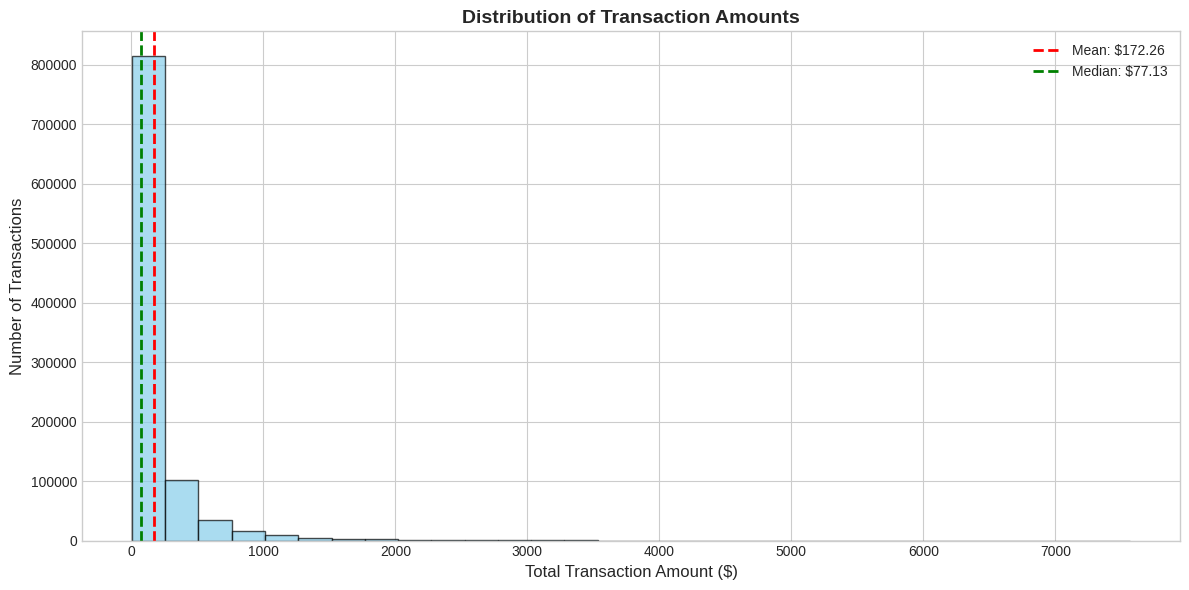

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# 1. Histogram of Total Amount spent per transaction
plt.figure(figsize=(12, 6))
plt.hist(df_pd['total_amount'], bins=30, edgecolor='black', color='skyblue', alpha=0.7)
plt.xlabel('Total Transaction Amount ($)', fontsize=12)
plt.ylabel('Number of Transactions', fontsize=12)
plt.title('Distribution of Transaction Amounts', fontsize=14, fontweight='bold')

mean_val = df_pd['total_amount'].mean()
median_val = df_pd['total_amount'].median()

plt.axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Mean: ${mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='dashed', linewidth=2, label=f'Median: ${median_val:.2f}')
plt.legend()
plt.tight_layout()
plt.show()

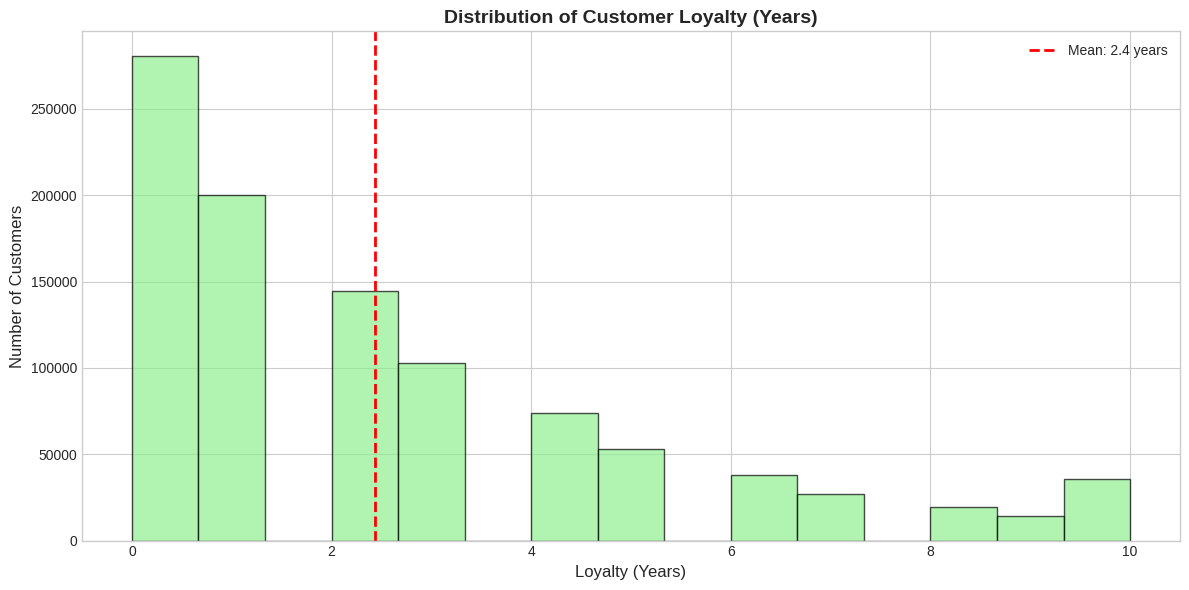

In [ ]:
# 2. Histogram of Loyalty Years
plt.figure(figsize=(12, 6))
plt.hist(df_pd['loyalty_years'], bins=15, edgecolor='black', color='lightgreen', alpha=0.7)
plt.xlabel('Loyalty (Years)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.title('Distribution of Customer Loyalty (Years)', fontsize=14, fontweight='bold')

mean_loyalty = df_pd['loyalty_years'].mean()
plt.axvline(mean_loyalty, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_loyalty:.1f} years')
plt.legend()
plt.tight_layout()
plt.show()

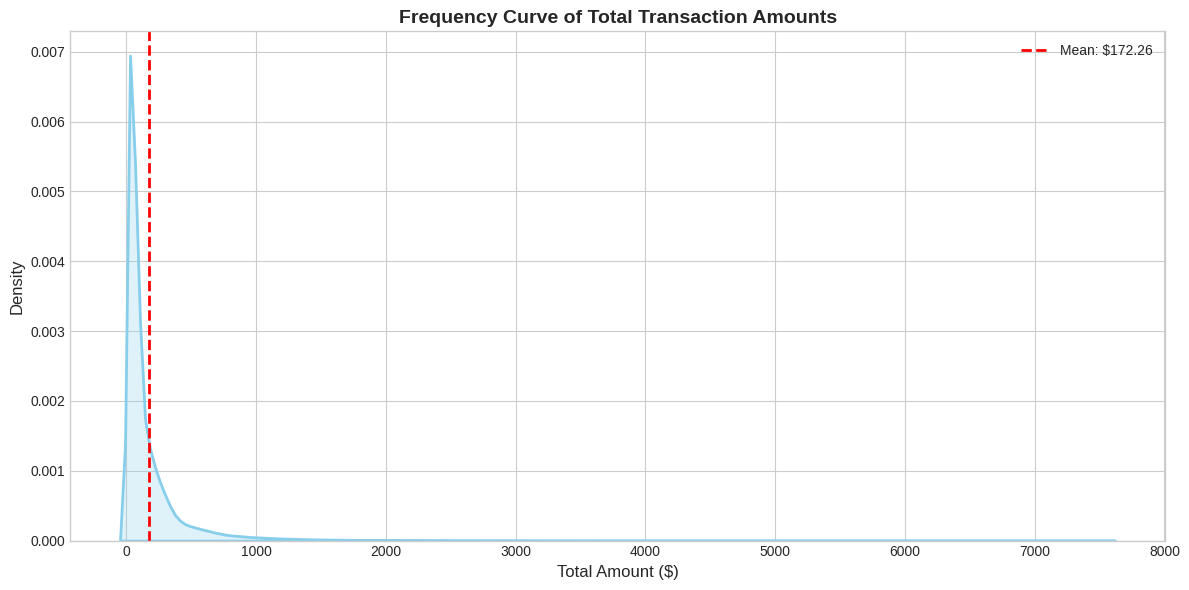

In [ ]:
# 3. Density Plot of Total Amount (Frequency Curve)
plt.figure(figsize=(12, 6))
sns.kdeplot(df_pd['total_amount'], fill=True, color='skyblue', linewidth=2)
plt.xlabel('Total Amount ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Frequency Curve of Total Transaction Amounts', fontsize=14, fontweight='bold')

mean_val = df_pd['total_amount'].mean()
plt.axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Mean: ${mean_val:.2f}')
plt.legend()
plt.tight_layout()
plt.show()

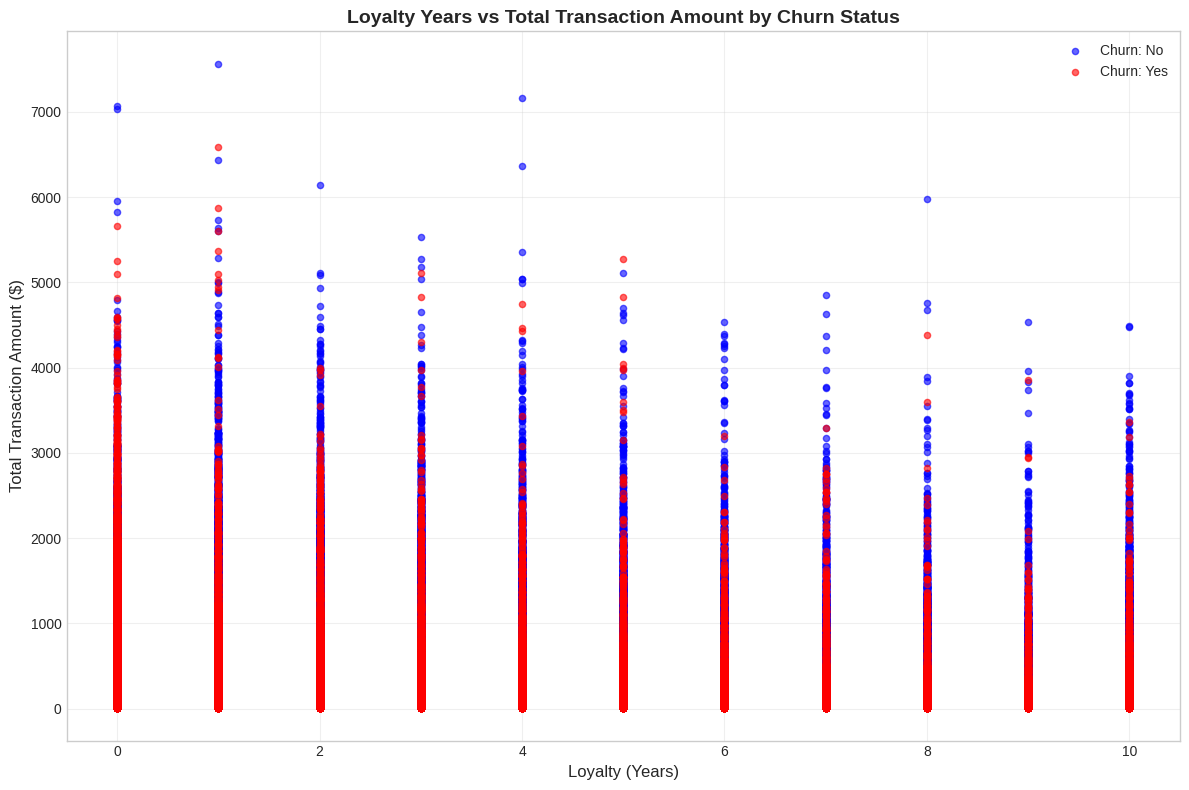

/tmp/ipykernel_895/2109069733.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='payment_method', y='total_amount', data=df_pd, palette='Set3')


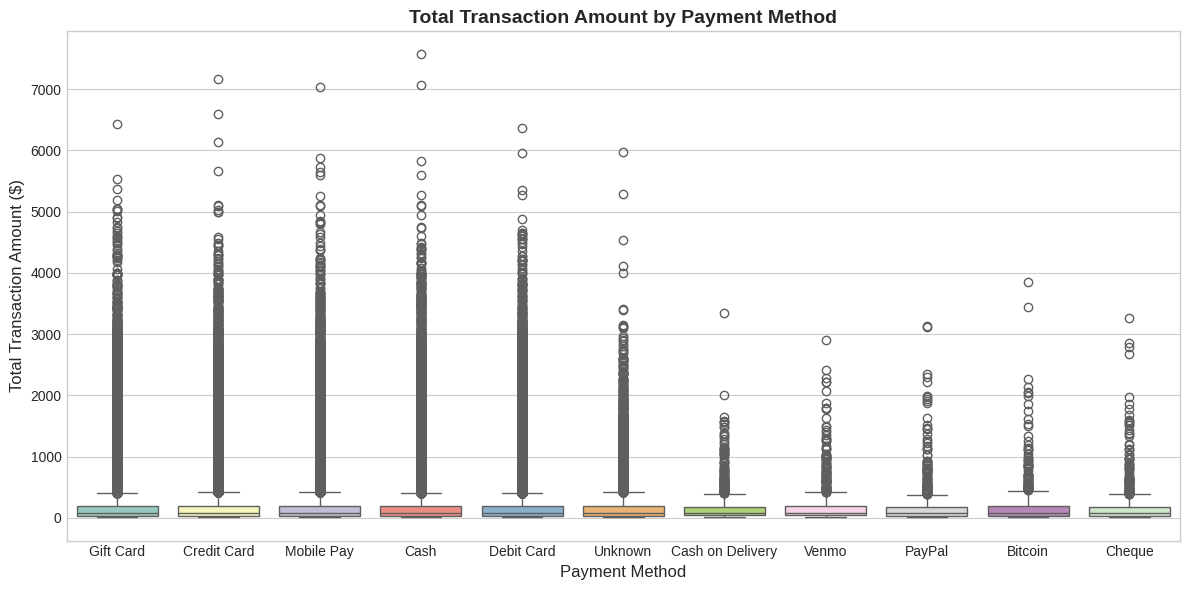

In [ ]:
# 4. Scatter Plot: Loyalty Years vs Total Amount (with Churn color)
plt.figure(figsize=(12, 8))
# Color by churn
colors = {'Yes': 'red', 'No': 'blue'}
for status in df_pd['churn'].unique():
    subset = df_pd[df_pd['churn'] == status]
    plt.scatter(subset['loyalty_years'], subset['total_amount'],
                label=f'Churn: {status}', alpha=0.6, color=colors.get(status, 'gray'), s=20)
plt.xlabel('Loyalty (Years)', fontsize=12)
plt.ylabel('Total Transaction Amount ($)', fontsize=12)
plt.title('Loyalty Years vs Total Transaction Amount by Churn Status', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Box Plot: Total Amount by Payment Method
plt.figure(figsize=(12, 6))
sns.boxplot(x='payment_method', y='total_amount', data=df_pd, palette='Set3')
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Total Transaction Amount ($)', fontsize=12)
plt.title('Total Transaction Amount by Payment Method', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

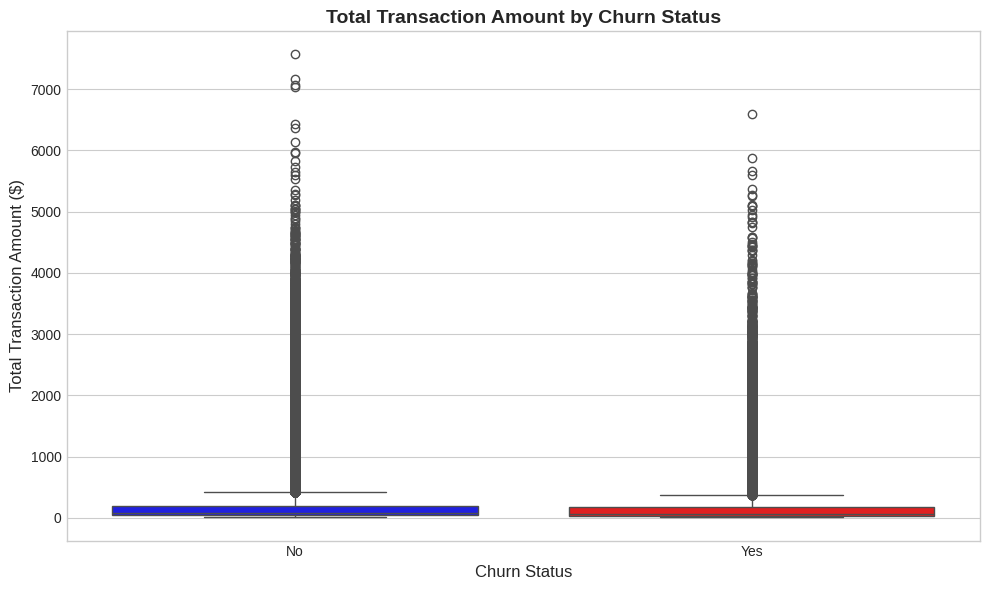

In [ ]:
# 6. Box Plot: Total Transaction Amount by Churn
plt.figure(figsize=(10, 6))
sns.boxplot(x='churn', y='total_amount', data=df_pd, palette=['blue', 'red'], hue='churn', legend=False)
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Total Transaction Amount ($)', fontsize=12)
plt.title('Total Transaction Amount by Churn Status', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

import plotly.express as px
# 7. 3D Scatter Plot (Using a sample to prevent browser rendering lag)
sample_df = df_pd.sample(n=5000, random_state=42)
fig = px.scatter_3d(
    sample_df,
    x='loyalty_years',
    y='total_amount',
    z='num_visits',
    color='churn',
    title='3D View of Customer Churn (Sample of 5,000 Transactions)',
    labels={
        'loyalty_years': 'Loyalty (Years)',
        'total_amount': 'Total Amount ($)',
        'num_visits': 'Number of Visits'
    },
    color_discrete_map={'Yes': 'red', 'No': 'blue'}
)
fig.update_traces(marker=dict(size=3))
fig.show()

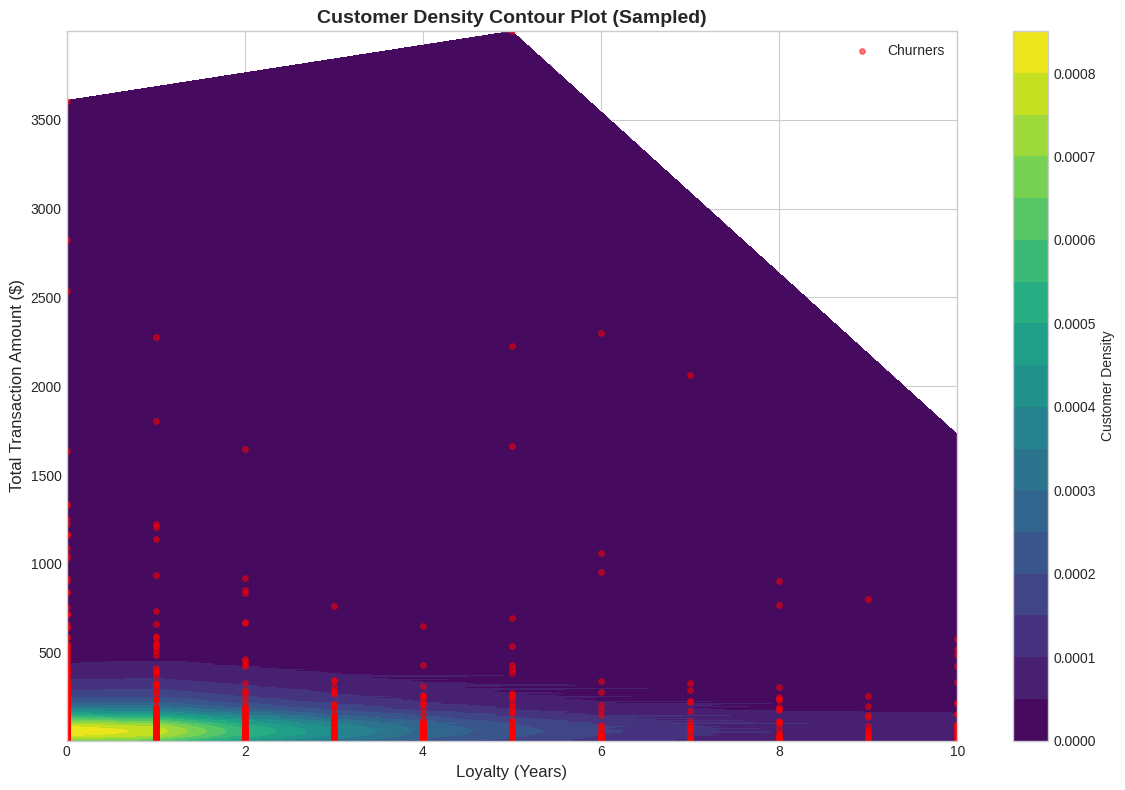

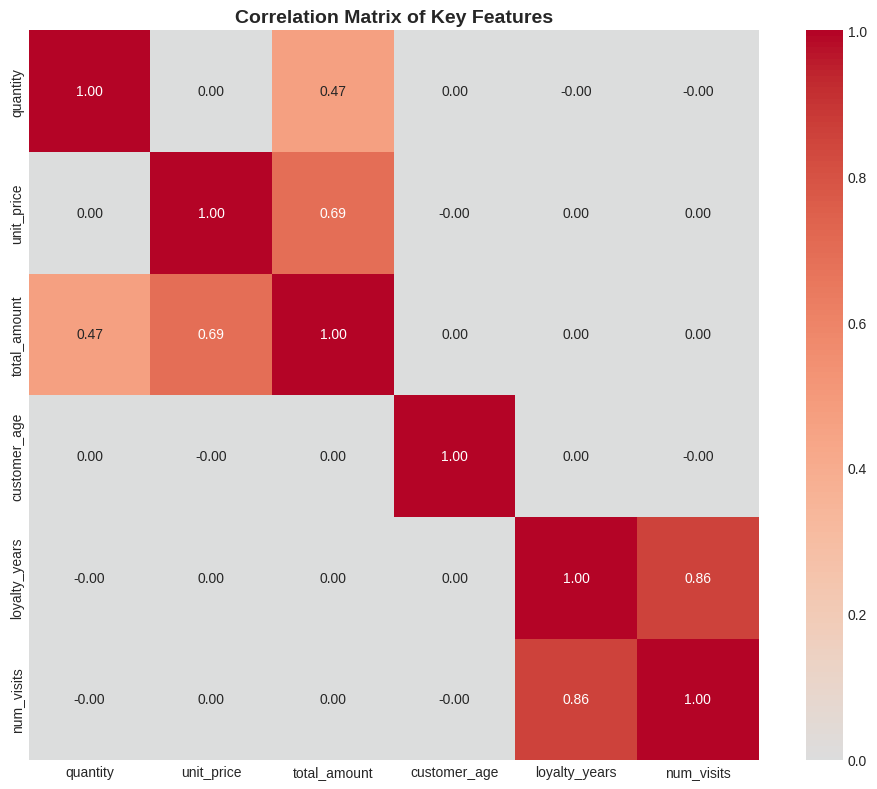

In [ ]:
from scipy.stats import gaussian_kde
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# To prevent kernel crash/hang on 1M rows, we sample 5,000 points for density calculation
sample_density = df_pd.sample(n=5000, random_state=42)

# 8. Contour Plot (Loyalty Years vs. Total Transaction Amount)
x = sample_density['loyalty_years'].values
y = sample_density['total_amount'].values

# Calculate density
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# Plot contour
plt.figure(figsize=(12, 8))
contour = plt.tricontourf(x, y, z, levels=20, cmap='viridis')
plt.colorbar(contour, label='Customer Density')
plt.xlabel('Loyalty (Years)', fontsize=12)
plt.ylabel('Total Transaction Amount ($)', fontsize=12)
plt.title('Customer Density Contour Plot (Sampled)', fontsize=14, fontweight='bold')

# Add scatter of churners from the sample
churners = sample_density[sample_density['churn'] == 'Yes']
plt.scatter(churners['loyalty_years'], churners['total_amount'],
            color='red', alpha=0.5, s=15, label='Churners')
plt.legend()
plt.tight_layout()
plt.show()

# 9. Correlation Heatmap of actual numeric features
plt.figure(figsize=(10, 8))
numeric_cols = ['quantity', 'unit_price', 'total_amount', 'customer_age', 'loyalty_years', 'num_visits']
corr_matrix = df_pd[numeric_cols].corr()

# Create heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Correlation Matrix of Key Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()